# Practice Notebook 3.2: One-Way ANOVA in Practice: Assumptions, Post-hoc Tests and Violations

Advanced Statistics Course, Brain Science, Period 2 (Week 3 practice)

In this notebook you run a complete one-way ANOVA workflow on a perception experiment: explore the data, check the assumptions, run and report the ANOVA, and locate the differences with post-hoc tests.
In Part B you will meet a dataset that **violates** an assumption and compare the classical ANOVA with its alternatives.

Please note: paper-and-pencil questions are followed directly by an **Answer** cell. For coding tasks, first work in the empty task cell(s), then compare with the **Solution** cell(s) below them.

**We assume independence of observations is guaranteed by the design (each participant contributes one value).**

In [ ]:
# Before running the analyses, we need to install a few Python libraries.
# Run the following command in your terminal or Jupyter Notebook (only needed once):
%pip install pandas numpy scipy matplotlib seaborn pingouin statsmodels

## Part A: The motion aftereffect

**Experiment**

After staring at a pattern that moves in one direction (e.g., a waterfall), a static pattern seems to drift in the **opposite** direction. This is the **motion aftereffect (MAE)**, caused by adaptation of direction-selective neurons in visual cortex (area MT/V5).

Participants adapted to a moving grating for one of **four adaptation durations** and then reported how long the illusory motion lasted on a static test pattern.

| Factor | Levels |
|---|---|
| **Adaptation duration** | 15 s / 30 s / 60 s / 120 s |

- Each participant was tested in only **one** adaptation condition (between-subjects), **12 participants per group** ($N = 48$).
- Dependent variable: **MAE duration** in seconds (`MAE_s`).

**Research question:** Does the duration of the motion aftereffect depend on how long participants adapted?

The data are embedded in the cell below (in a real study you would load them from a file). Run it.

In [2]:
import io
import numpy as np
import pandas as pd

mae_csv = """
Participant,Adaptation,MAE_s
P14,30s,10.96
P16,30s,6.49
P23,30s,5.89
P37,120s,8.55
P41,120s,8.09
P25,60s,8.6
P02,15s,2.53
P21,30s,9.18
P11,15s,8.71
P35,60s,6.19
P30,60s,6.76
P45,120s,9.15
P33,60s,6.2
P19,30s,2.68
P18,30s,6.87
P34,60s,7.78
P28,60s,5.08
P42,120s,10.92
P10,15s,2.7
P03,15s,1.53
P31,60s,9.24
P17,30s,5.43
P22,30s,6.66
P06,15s,6.32
P32,60s,7.86
P44,120s,6.73
P07,15s,4.26
P36,60s,9.62
P39,120s,6.7
P12,15s,2.71
P01,15s,5.38
P13,30s,6.94
P08,15s,5.07
P47,120s,9.3
P38,120s,10.05
P27,60s,8.88
P46,120s,7.68
P09,15s,5.94
P43,120s,10.05
P15,30s,6.11
P29,60s,8.91
P40,120s,11.35
P24,30s,6.93
P20,30s,5.2
P04,15s,-0.77
P26,60s,8.16
P05,15s,3.6
P48,120s,11.04
"""
df_mae = pd.read_csv(io.StringIO(mae_csv.strip()))
order = ["15s", "30s", "60s", "120s"]   # logical order of the groups (used for tables and plots)
print(df_mae.head())
print("\nShape:", df_mae.shape)

  Participant Adaptation  MAE_s
0         P14        30s  10.96
1         P16        30s   6.49
2         P23        30s   5.89
3         P37       120s   8.55
4         P41       120s   8.09

Shape: (48, 3)


### A1. Explore the data

1. What are the independent and dependent variables, and at which level of measurement?
2. Compute the mean, standard deviation, median and n of `MAE_s` per adaptation group (in the logical order 15 s → 120 s).
3. Make a boxplot with the individual data points on top.
4. Before testing: does the MAE seem to grow with adaptation duration? Between which neighbouring groups do you expect the difference to be too small to be significant?

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# TODO 1: descriptives per group (mean, std, median, count) in the order given by `order`

# TODO 2: boxplot + stripplot

**Solution**

            mean   std  median  count
Adaptation                           
15s         4.00  2.50    3.93     12
30s         6.61  2.03    6.58     12
60s         7.77  1.42    8.01     12
120s        9.13  1.61    9.23     12


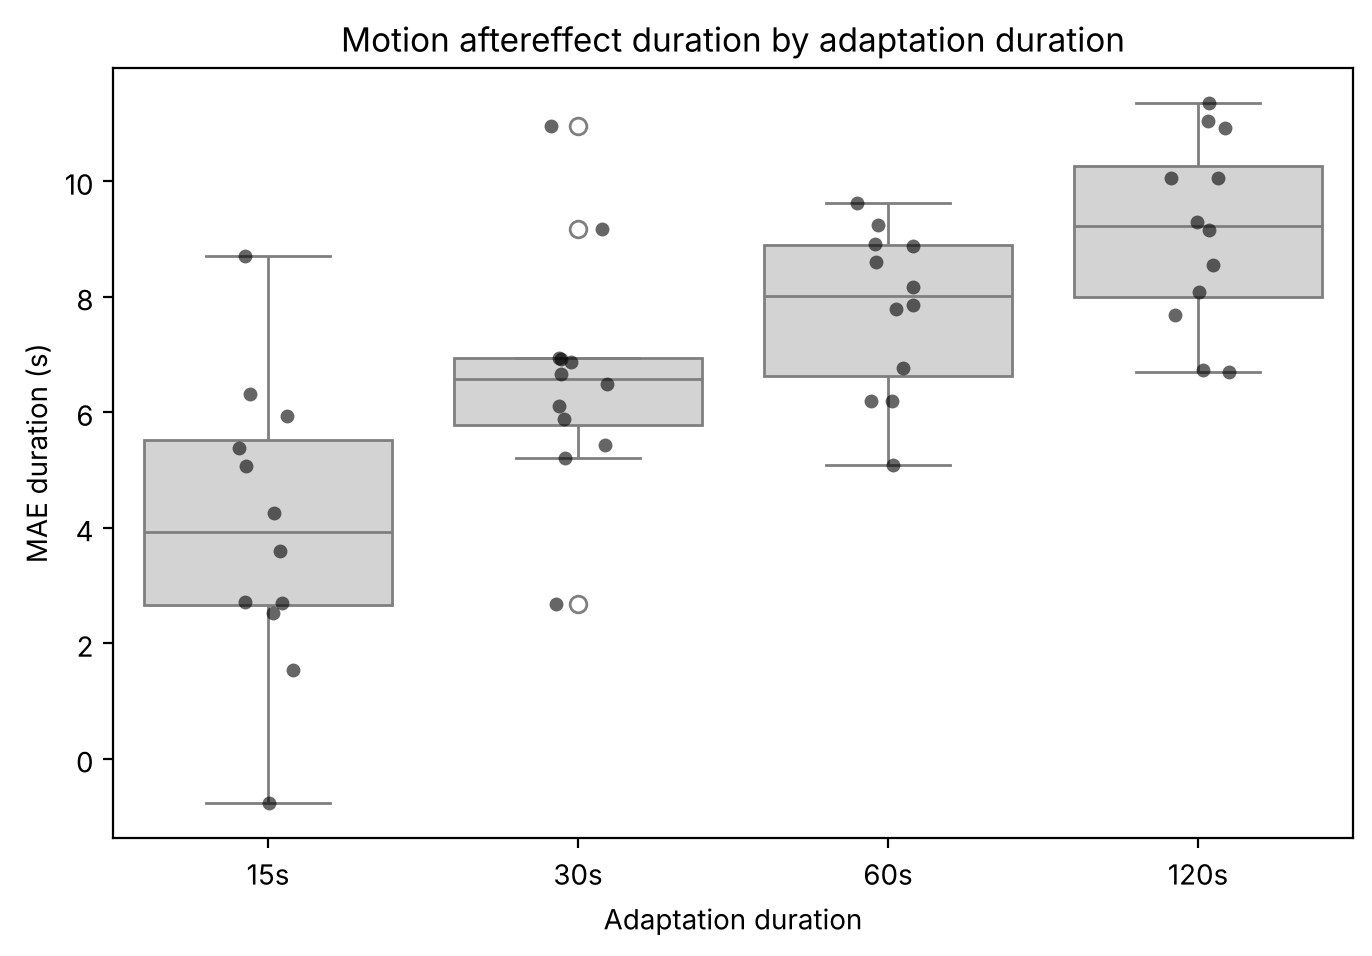

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

desc = df_mae.groupby("Adaptation")["MAE_s"].agg(["mean", "std", "median", "count"]).loc[order]
print(desc.round(2))

plt.figure(figsize=(8, 5))
sns.boxplot(x="Adaptation", y="MAE_s", data=df_mae, order=order, color="lightgrey")
sns.stripplot(x="Adaptation", y="MAE_s", data=df_mae, order=order, color="black", alpha=0.6)
plt.title("Motion aftereffect duration by adaptation duration")
plt.ylabel("MAE duration (s)")
plt.xlabel("Adaptation duration")
plt.show()

**Answer**

1. **IV:** adaptation duration, a categorical factor with 4 levels (treated as nominal in ANOVA, although it is ordered). **DV:** MAE duration in seconds, continuous (ratio scale).
2. Descriptives:

| Adaptation | Mean (s) | SD (s) | Median (s) | n |
|---|---:|---:|---:|---:|
| 15 s | 4.00 | 2.50 | 3.93 | 12 |
| 30 s | 6.61 | 2.03 | 6.58 | 12 |
| 60 s | 7.77 | 1.42 | 8.01 | 12 |
| 120 s | 9.13 | 1.61 | 9.23 | 12 |

3. / 4. The MAE grows with adaptation duration, but the increase **levels off**: the largest step is 15 s → 30 s (≈ 2.6 s), while 30 s → 60 s and 60 s → 120 s add only ≈ 1.2–1.4 s each, which is small relative to the within-group SDs (≈ 1.4–2.5 s). Those neighbouring pairs may not differ significantly.

### A2. Check the assumptions

1. List the three assumptions of a one-way between-subjects ANOVA. Which one can't be tested statistically, and how is it ensured?
2. Test normality **within each group** with the Shapiro–Wilk test (`pg.normality(data, dv, group)`). State $H_0$ and your conclusion.
3. Test homogeneity of variances with Levene's test (`pg.homoscedasticity(data, dv, group)`). State $H_0$ and your conclusion.
4. The 15 s group has the largest SD (2.50) and the 60 s group the smallest (1.42). Does this contradict your Levene result?

In [ ]:
import pingouin as pg

# TODO 1: Shapiro-Wilk per group

# TODO 2: Levene's test

**Solution**

In [6]:
import pingouin as pg

print("Shapiro-Wilk per group:\n", pg.normality(data=df_mae, dv="MAE_s", group="Adaptation").loc[order].round(3))
print("\nLevene's test:\n", pg.homoscedasticity(data=df_mae, dv="MAE_s", group="Adaptation").round(3))

Shapiro-Wilk per group:
                 W   pval  normal
Adaptation                      
15s         0.986  0.998    True
30s         0.916  0.257    True
60s         0.936  0.450    True
120s        0.940  0.500    True

Levene's test:
             W   pval  equal_var
levene  1.066  0.373       True


**Answer**

1. Assumptions:
   - **Independence of observations**: not tested; ensured by the **design** (random assignment, each participant in one group only, no influence between participants).
   - **Normality within each group**: Shapiro–Wilk test per group.
   - **Homogeneity of variances**: Levene's test.
2. Shapiro–Wilk, $H_0$: the data in the group are normally distributed. All p-values are > .05 (15 s: .998, 30 s: .257, 60 s: .450, 120 s: .500), so we **do not reject** normality in any group. Assumption met.
3. Levene, $H_0$: the population variances are equal across groups ($H_A$: at least one differs). $W = 1.07$, $p = .373 > .05$, so we **do not reject** equal variances. Assumption met.
4. No. With $n = 12$ per group, SDs naturally fluctuate between samples; a ratio of about 1.8 between the largest and smallest SD is not enough evidence that the population variances differ. Levene's test formalises this judgement (it runs an ANOVA on the absolute deviations $|X_{ij} - \bar X_i|$).

### A3. Run and report the one-way ANOVA

1. State $H_0$ and $H_1$.
2. Run the ANOVA with `pg.anova(..., detailed=True)`.
3. Using only the SS and df columns of the output, recompute $MS_B$, $MS_W$ and $F$ yourself, and get the p-value with `scipy.stats.f.sf`.
4. Compute $\eta^2 = SS_B / SS_T$.
5. Write the result in the standard reporting format and interpret it.

In [ ]:
from scipy import stats

# TODO 1: one-way ANOVA with pingouin (detailed=True)

# TODO 2: recompute MS_between, MS_within, F and p from SS and DF

# TODO 3: eta squared

**Solution**

In [8]:
from scipy import stats

aov = pg.anova(data=df_mae, dv="MAE_s", between="Adaptation", detailed=True)
print(aov.round(4))

ss_b, ss_w = aov.loc[0, "SS"], aov.loc[1, "SS"]
df_b, df_w = aov.loc[0, "DF"], aov.loc[1, "DF"]
ms_b, ms_w = ss_b / df_b, ss_w / df_w
F = ms_b / ms_w
p = stats.f.sf(F, df_b, df_w)
eta2 = ss_b / (ss_b + ss_w)

print(f"\nMS_between = {ss_b:.2f} / {df_b} = {ms_b:.2f}")
print(f"MS_within  = {ss_w:.2f} / {df_w} = {ms_w:.2f}")
print(f"F({df_b}, {df_w}) = {F:.2f}, p = {p:.2e}, eta^2 = {eta2:.2f}")

       Source        SS  DF       MS        F  p_unc     np2
0  Adaptation  171.0638   3  57.0213  15.1815    0.0  0.5086
1      Within  165.2623  44   3.7560      NaN    NaN     NaN

MS_between = 171.06 / 3 = 57.02
MS_within  = 165.26 / 44 = 3.76
F(3, 44) = 15.18, p = 6.37e-07, eta^2 = 0.51


**Answer**

1. $H_0: \mu_{15} = \mu_{30} = \mu_{60} = \mu_{120}$ (adaptation duration has no effect on MAE duration). $H_1$: at least one population mean differs (not necessarily all).
2. / 3. $SS_B = 171.06$ ($df = 3$), $SS_W = 165.26$ ($df = 44$). $MS_B = 57.02$, $MS_W = 3.76$, $F = 57.02 / 3.76 = 15.18$, $p = 6.4 \times 10^{-7}$.
4. $\eta^2 = 171.06 / 336.33 = .51$: about half of the variance in MAE duration is explained by adaptation duration. (In a one-way design, pingouin's `np2` equals $\eta^2$.)
5. **Report:** The duration of adaptation had a significant effect on MAE duration, $F(3, 44) = 15.18$, $p < .001$, $\eta^2 = .51$.
   **Interpretation:** at least two adaptation durations lead to different MAE durations. The ANOVA does **not** tell us which ones, so we need post-hoc tests.

### A4. Planning the post-hoc tests (paper and pencil)

1. How many pairwise comparisons are possible between the 4 groups?
2. What per-comparison $\alpha$ would a Bonferroni correction use?
3. Without any correction, what would the familywise error rate be (assuming independent tests)?
4. Which post-hoc test (Tukey HSD, Bonferroni, Scheffé) is the most natural choice here, and why?
5. Why should post-hoc tests only be interpreted after a significant omnibus F?

**Answer**

1. $m = \frac{4 \cdot 3}{2} = 6$ comparisons.
2. $\alpha_{Bonf} = 0.05 / 6 \approx 0.0083$ (equivalently: multiply each p-value by 6, capped at 1).
3. $1 - 0.95^6 \approx 0.265$.
4. **Tukey HSD**: we want **all pairwise** comparisons in a **balanced** design (12 per group), which is exactly what Tukey is built for; it controls the familywise error rate while being less conservative than Bonferroni. Scheffé is intended for complex contrasts (e.g., 15 s vs the average of all other groups) and would be unnecessarily conservative for simple pairs.
5. The omnibus F tells us whether there is any difference at all. If F is not significant, there is no overall evidence for an effect, and searching through pairs anyway reintroduces the multiple-testing problem the ANOVA was meant to avoid.

### A5. Tukey HSD

1. Run Tukey HSD with **statsmodels** (`pairwise_tukeyhsd(endog, groups)`) and with **pingouin** (`pg.pairwise_tukey`).
2. Which pairs differ significantly?
3. Look at the `meandiff` column (statsmodels) and the `diff` column (pingouin) for the pair 120 s vs 15 s. Explain the sign of each. What is the sign convention of each package?
4. Summarise the post-hoc results in one or two sentences, in the context of motion adaptation.

In [ ]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# TODO 1: Tukey HSD with statsmodels

# TODO 2: Tukey HSD with pingouin

**Solution**

In [10]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey_sm = pairwise_tukeyhsd(endog=df_mae["MAE_s"], groups=df_mae["Adaptation"], alpha=0.05)
print(tukey_sm)

tukey_pg = pg.pairwise_tukey(data=df_mae, dv="MAE_s", between="Adaptation")
print("\n", tukey_pg[["A", "B", "mean_A", "mean_B", "diff", "p_tukey"]].round(4))

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
  120s    15s  -5.1358    0.0 -7.2483 -3.0233   True
  120s    30s  -2.5225 0.0135  -4.635   -0.41   True
  120s    60s  -1.3608 0.3258 -3.4733  0.7517  False
   15s    30s   2.6133 0.0099  0.5008  4.7258   True
   15s    60s    3.775 0.0001  1.6625  5.8875   True
   30s    60s   1.1617 0.4649 -0.9508  3.2742  False
----------------------------------------------------

       A    B  mean_A  mean_B    diff  p_tukey
0  120s  15s  9.1342  3.9983  5.1358   0.0000
1  120s  30s  9.1342  6.6117  2.5225   0.0135
2  120s  60s  9.1342  7.7733  1.3608   0.3258
3   15s  30s  3.9983  6.6117 -2.6133   0.0099
4   15s  60s  3.9983  7.7733 -3.7750   0.0001
5   30s  60s  6.6117  7.7733 -1.1617   0.4649


**Answer**

2. Significant pairs ($p_{Tukey} < .05$): **15 s vs 30 s** ($p = .010$), **15 s vs 60 s** ($p < .001$), **15 s vs 120 s** ($p < .001$), **30 s vs 120 s** ($p = .014$).
   Not significant: **30 s vs 60 s** ($p = .465$) and **60 s vs 120 s** ($p = .326$).
3. Sign conventions (note that both packages sort the groups **alphabetically**, so "120s" comes before "15s"):
   - **statsmodels** `meandiff` = mean(group2) − mean(group1) = $4.00 - 9.13 = -5.14$. Negative means **group1 (120 s) has the higher mean**.
   - **pingouin** `diff` = mean(A) − mean(B) = $9.13 - 4.00 = +5.14$.
   - Same comparison, opposite signs: always check which convention the output uses before interpreting the direction.
4. Longer adaptation produces a longer MAE: 15 s gives a shorter MAE than all other durations, and 120 s gives a longer MAE than 30 s. Neighbouring durations beyond 30 s (30 vs 60 s, 60 vs 120 s) do not differ significantly, consistent with the MAE growing quickly at first and then levelling off.

### A6. Bonferroni-corrected pairwise t-tests

1. Run all pairwise t-tests with a Bonferroni correction: `pg.pairwise_tests(data, dv, between, padjust="bonf")`. Compare the corrected p-values (`p_corr`) with the Tukey p-values.
2. Which pair is significant with Tukey but **not** with Bonferroni? Why can this happen?
3. Check one corrected p-value by hand: what is the relationship between `p_unc` and `p_corr`?

In [ ]:
# TODO 1: Bonferroni-corrected pairwise t-tests

# TODO 2: put the Tukey and Bonferroni p-values side by side

**Solution**

In [12]:
bonf = pg.pairwise_tests(data=df_mae, dv="MAE_s", between="Adaptation", padjust="bonf")
comparison = bonf[["A", "B", "T", "p_unc", "p_corr"]].copy()
comparison["p_tukey"] = tukey_pg["p_tukey"].values      # same pair order (alphabetical) in both tables
print(comparison.round(4))

      A    B       T   p_unc  p_corr  p_tukey
0  120s  15s  5.9708  0.0000  0.0000   0.0000
1  120s  30s  3.3666  0.0028  0.0167   0.0135
2  120s  60s  2.1921  0.0392  0.2355   0.3258
3   15s  30s -2.8073  0.0103  0.0616   0.0099
4   15s  60s -4.5426  0.0002  0.0010   0.0001
5   30s  60s -1.6233  0.1188  0.7126   0.4649


**Answer**

1. / 2. All pairs agree except **15 s vs 30 s**: Tukey $p = .010$ (significant), Bonferroni $p_{corr} = .062$ (not significant).
   Bonferroni is **more conservative**: it divides $\alpha$ by the number of comparisons (here 6), which over-corrects because the comparisons are not independent. Tukey uses the distribution of the largest difference among all pairs (studentized range) and the pooled $MS_W$ from all 48 participants, so it keeps the familywise error rate at .05 with more power for all-pairwise comparisons.
3. $p_{corr} = \min(1, \; m \cdot p_{unc})$ with $m = 6$. For 15 s vs 30 s: $6 \times .0103 = .062$.

## Part B: When an assumption is violated: visual search

**Experiment**

In a **visual search** task, participants look for a red **T** among red **L**s. Each participant searched displays with only one **set size** (number of items: 4, 8 or 16), **15 participants per group** ($N = 45$). The DV is the participant's mean search time in ms (`SearchRT_ms`).

**Questions**
1. Compute descriptives per set size. What do you notice about the SDs?
2. Check normality (Shapiro–Wilk) and homogeneity of variances (Levene). Which assumption is violated?
3. Run three analyses: the classical one-way ANOVA, **Welch's ANOVA** (`pg.welch_anova`) and the **Kruskal–Wallis** test (`pg.kruskal`). Do they lead to the same conclusion?
4. Which result would you report, and why?

In [13]:
search_csv = """
Participant,SetSize,SearchRT_ms
S21,8,648
S19,8,815
S14,4,602
S22,8,993
S02,4,732
S11,4,593
S16,8,907
S18,8,612
S25,8,700
S43,16,516
S28,8,633
S38,16,731
S30,8,712
S23,8,776
S10,4,685
S33,16,1017
S03,4,683
S35,16,846
S39,16,565
S06,4,546
S34,16,574
S42,16,1420
S31,16,1136
S37,16,568
S12,4,693
S01,4,622
S13,4,677
S32,16,552
S17,8,586
S45,16,873
S07,4,698
S08,4,608
S36,16,740
S27,8,540
S44,16,1363
S09,4,701
S41,16,916
S15,4,826
S29,8,510
S40,16,1006
S24,8,629
S20,8,814
S04,4,604
S26,8,731
S05,4,705
"""
df_search = pd.read_csv(io.StringIO(search_csv.strip()))
print(df_search.head())
print("\nShape:", df_search.shape)

  Participant  SetSize  SearchRT_ms
0         S21        8          648
1         S19        8          815
2         S14        4          602
3         S22        8          993
4         S02        4          732

Shape: (45, 3)


In [ ]:
# TODO 1: descriptives per SetSize (+ optional boxplot)

# TODO 2: Shapiro-Wilk per group and Levene's test

# TODO 3: classical ANOVA, Welch ANOVA, Kruskal-Wallis

**Solution**

          mean    std  median  count
SetSize                             
4        665.0   69.8   683.0     15
8        707.1  135.2   700.0     15
16       854.9  291.6   846.0     15


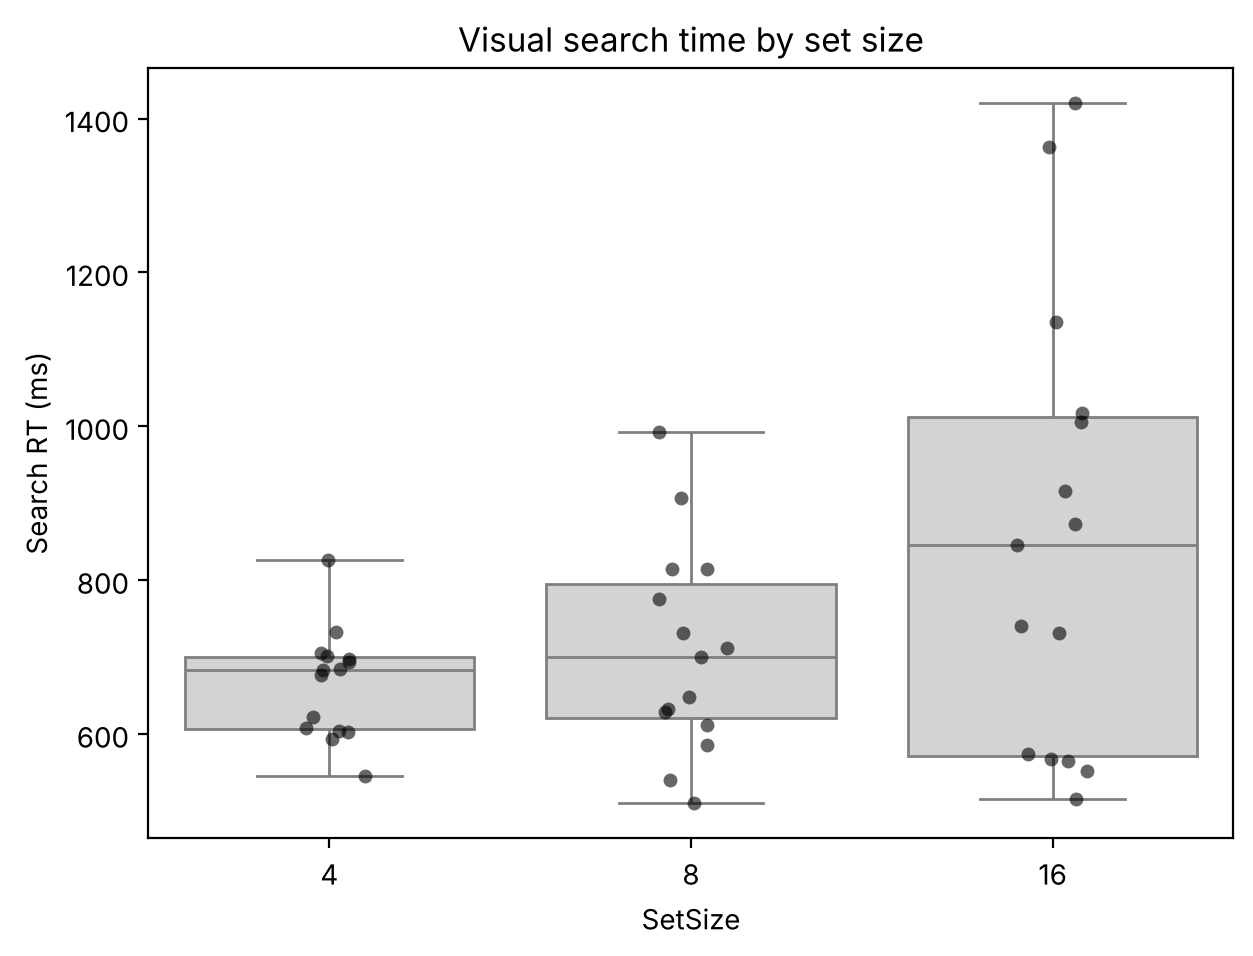


Shapiro-Wilk:
              W   pval  normal
SetSize                      
8        0.964  0.760    True
4        0.938  0.355    True
16       0.911  0.138    True

Levene:
               W    pval  equal_var
levene  10.7139  0.0002      False

Classical ANOVA:
     Source            SS  DF           MS       F   p_unc     np2
0  SetSize  2.983190e+05   2  149159.4889  4.1376  0.0229  0.1646
1   Within  1.514087e+06  42   36049.6825     NaN     NaN     NaN

Welch ANOVA:
     Source  ddof1    ddof2       F   p_unc     np2
0  SetSize      2  23.1457  3.2457  0.0572  0.1646

Kruskal-Wallis:
           Source  ddof1       H   p_unc
Kruskal  SetSize      2  3.2549  0.1964


In [15]:
print(df_search.groupby("SetSize")["SearchRT_ms"].agg(["mean", "std", "median", "count"]).round(1))

plt.figure(figsize=(7, 5))
sns.boxplot(x="SetSize", y="SearchRT_ms", data=df_search, color="lightgrey")
sns.stripplot(x="SetSize", y="SearchRT_ms", data=df_search, color="black", alpha=0.6)
plt.title("Visual search time by set size")
plt.ylabel("Search RT (ms)")
plt.show()

print("\nShapiro-Wilk:\n", pg.normality(data=df_search, dv="SearchRT_ms", group="SetSize").round(3))
print("\nLevene:\n", pg.homoscedasticity(data=df_search, dv="SearchRT_ms", group="SetSize").round(4))

print("\nClassical ANOVA:\n", pg.anova(data=df_search, dv="SearchRT_ms", between="SetSize", detailed=True).round(4))
print("\nWelch ANOVA:\n", pg.welch_anova(data=df_search, dv="SearchRT_ms", between="SetSize").round(4))
print("\nKruskal-Wallis:\n", pg.kruskal(data=df_search, dv="SearchRT_ms", between="SetSize").round(4))

**Answer**

1. Means increase with set size (4: 665 ms, 8: 707 ms, 16: 855 ms), and so do the **SDs**: 70 → 135 → 292 ms. The spread for set size 16 is about four times that of set size 4, a typical pattern for RT data (longer RTs vary more).
2. Shapiro–Wilk: all p > .05 (.355, .760, .138), so normality is not rejected. **Levene: $W = 10.71$, $p = .0002$**: the homogeneity-of-variances assumption is **violated**.
3. The three tests disagree:

| Test | Statistic | p | Decision ($\alpha = .05$) |
|---|---|---|---|
| Classical ANOVA | $F(2, 42) = 4.14$ | .023 | reject $H_0$ |
| Welch's ANOVA | $F(2, 23.1) = 3.25$ | .057 | do not reject |
| Kruskal–Wallis | $H(2) = 3.25$ | .196 | do not reject |

4. Report **Welch's ANOVA**: variances are clearly unequal while normality holds, and Welch's ANOVA does not assume equal variances (note the adjusted, non-integer denominator df). The classical F pools the variances into one $MS_W$, which is not appropriate here, so its p-value cannot be trusted. Conclusion: there is no significant evidence that mean search time differs between set sizes, $F_{Welch}(2, 23.1) = 3.25$, $p = .057$, although the trend is in the expected direction. Kruskal–Wallis (rank-based) would be the alternative if normality were violated, but it tests a different hypothesis (distributions/medians rather than means).

### Optional Follow-Up Thought
The visual-search effect is weak here partly because **between-subject** differences in overall speed inflate the within-group variance. How would you redesign the experiment so that each participant serves as their own control? What would the data table look like, and which variance component could then be removed from the error term?
Next week we'll explore this with **repeated-measures ANOVA**.